## Tahap 0: Import dan Menentukan Lokasi Dataset

Fungsi `cari_root` sama dengan yang ada di dua notebook sebelumnya, supaya semua
notebook menunjuk ke folder `Dataset` yang sama.

Library yang dipakai sedikit saja. Numpy untuk seluruh perhitungan vektor, pandas
untuk membaca XLSX, PCA dari scikit-learn untuk memproyeksikan vektor ke dua
dimensi agar bisa digambar, dan matplotlib untuk grafiknya.

In [1]:
from pathlib import Path
import collections
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


def cari_root(mulai: Path) -> Path:
    for p in (mulai, *mulai.parents):
        if (p / "Praktikum").is_dir():
            return p
    return mulai
ROOT = cari_root(Path.cwd().resolve())
DATASET_DIR = ROOT / "Dataset"

FILE_XLSX = DATASET_DIR / "dataset_leetcode_cleaned.xlsx"   # dihasilkan notebook 1
EMBED_DIR = DATASET_DIR / "embedding"
EMBED_DIR.mkdir(parents=True, exist_ok=True)
FILE_MODEL = EMBED_DIR / "word2vec_model.npz"               # cache hasil pelatihan

print(f"Root project   : {ROOT}")
print(f"Berkas sumber  : {FILE_XLSX}")
print(f"Folder keluaran: {EMBED_DIR}")

Root project   : /Users/alif/PycharmProjects/Text-Mining
Berkas sumber  : /Users/alif/PycharmProjects/Text-Mining/Dataset/dataset_leetcode_cleaned.xlsx
Folder keluaran: /Users/alif/PycharmProjects/Text-Mining/Dataset/embedding


## Tahap 1: Membaca Dataset Hasil Grabbing

Berkas yang dibaca sama persis dengan yang dipakai notebook 2, yaitu keluaran dari
`01_Pengambilan_Data.ipynb`.

Kolom yang dipakai cuma `Cleaned_Description`, teks yang sudah melewati case
folding, pembuangan simbol, stopword removal, dan lemmatization. Kolom
`Problem Name` dipakai belakangan untuk menampilkan judul soal saat mengukur
kemiripan antar dokumen.

In [2]:
if not FILE_XLSX.exists():
    raise FileNotFoundError(
        f"Berkas belum ada: {FILE_XLSX}\n"
        "Jalankan dulu 01_Pengambilan_Data.ipynb sampai sel terakhir."
    )

df = pd.read_excel(FILE_XLSX)
df = df.dropna(subset=['Cleaned_Description']).reset_index(drop=True)

print(f"Berhasil membaca: {FILE_XLSX.name}")
print(f"Jumlah dokumen  : {len(df)}")
display(df[['Problem Name', 'Difficulty']].head())

Berhasil membaca: dataset_leetcode_cleaned.xlsx
Jumlah dokumen  : 90


,Problem Name,Difficulty
0,Two Sum,Easy
1,Longest Substring Without Repeating Characters,Medium
2,Median of Two Sorted Arrays,Hard
3,Longest Palindromic Substring,Medium
4,Zigzag Conversion,Medium


## Tahap 2: Menyiapkan Korpus

Word2Vec tidak membaca kalimat utuh, melainkan daftar token per dokumen. Jadi
kolom teks dipecah kembali jadi list kata dengan `split()`.

Pemecahannya cukup pakai `split()` biasa, bukan tokenizer NLTK lagi, karena teks di
kolom ini sudah bersih dan antar kata sudah dipisah spasi tunggal sejak notebook
pertama.

Angka yang muncul di sini penting untuk diingat saat presentasi. Korpus ini
tergolong sangat kecil untuk ukuran Word2Vec, dan itu berpengaruh ke kualitas
hasilnya nanti.

In [3]:
korpus_kata = [str(teks).split() for teks in df['Cleaned_Description']]

semua_token = [w for dok in korpus_kata for w in dok]
panjang = sorted(len(d) for d in korpus_kata)

print(f"Jumlah dokumen      : {len(korpus_kata)}")
print(f"Total token         : {len(semua_token):,}")
print(f"Kata unik           : {len(set(semua_token)):,}")
print(f"Token per dokumen   : min {panjang[0]}, median {panjang[len(panjang)//2]}, max {panjang[-1]}")
print(f"\nContoh 15 token dokumen pertama:")
print(" ", korpus_kata[0][:15])

Jumlah dokumen      : 90
Total token         : 5,290
Kata unik           : 994
Token per dokumen   : min 12, median 52, max 143

Contoh 15 token dokumen pertama:
  ['array', 'integer', 'nums', 'integer', 'target', 'index', 'two', 'number', 'add', 'target', 'may', 'assume', 'would', 'exactly', 'one']


## Tahap 3: Membangun Kosakata

Dua hal dikerjakan di sel ini.

**Penyaringan kata jarang.** Kata yang muncul kurang dari tiga kali dibuang lewat
`MIN_COUNT`. Alasannya, Word2Vec belajar dari konteks, dan kata yang cuma muncul
sekali atau dua kali tidak punya cukup contoh konteks untuk dipelajari. Vektornya
akan jadi acak dan cuma menambah beban.

**Tabel negative sampling.** Nanti saat melatih, model butuh mengambil kata acak
sebagai contoh negatif. Pengambilannya tidak rata, melainkan mengikuti frekuensi
kata yang dipangkatkan 0,75. Angka 0,75 ini berasal dari paper asli Word2Vec.
Efeknya, kata yang sering muncul tetap lebih mungkin terpilih, tapi dominasinya
ditekan sehingga kata yang jarang masih kebagian.

In [4]:
MIN_COUNT = 3     # kata harus muncul minimal 3 kali untuk masuk kosakata

frekuensi = collections.Counter(semua_token)
kosakata = [w for w, c in frekuensi.most_common() if c >= MIN_COUNT]
indeks_kata = {w: i for i, w in enumerate(kosakata)}
V = len(kosakata)

# Korpus diubah jadi deretan indeks angka supaya proses latihnya cepat
korpus_indeks = [[indeks_kata[w] for w in dok if w in indeks_kata] for dok in korpus_kata]
token_terpakai = sum(len(d) for d in korpus_indeks)

# Tabel peluang negative sampling, frekuensi dipangkatkan 0,75 seperti paper aslinya
bobot_neg = np.array([frekuensi[w] for w in kosakata], dtype=np.float64) ** 0.75
peluang_neg = bobot_neg / bobot_neg.sum()

print(f"Kata unik sebelum disaring : {len(frekuensi):,}")
print(f"Kosakata setelah MIN_COUNT={MIN_COUNT} : {V:,}")
print(f"Token yang terpakai        : {token_terpakai:,} dari {len(semua_token):,}")
print(f"\n10 kata tersering: {kosakata[:10]}")

Kata unik sebelum disaring : 994
Kosakata setelah MIN_COUNT=3 : 441
Token yang terpakai        : 4,550 dari 5,290

10 kata tersering: ['nums', 'array', 'integer', 'n', 'string', 'word', 'element', 'k', 'target', 'one']


## Tahap 4: Cara Skip-gram Membaca Teks

Sebelum melatih, bagian ini memperlihatkan data latihnya seperti apa.

Skip-gram bekerja dengan menggeser jendela di sepanjang teks. Untuk tiap posisi,
kata di tengah disebut kata pusat, dan kata di sekitarnya dalam radius tertentu
disebut kata konteks. Model dilatih untuk menebak kata konteks dari kata pusat.

Jadi satu kalimat menghasilkan banyak pasangan latih. Dari situlah model belajar
bahwa dua kata yang sering muncul berdampingan punya hubungan.

Sel ini mencetak pasangan yang terbentuk dari potongan dokumen pertama, supaya
bentuk data latihnya kelihatan konkret.

In [5]:
WINDOW = 5   # radius jendela konteks

def contoh_pasangan(dokumen, window=2, batas=10):
    """Tampilkan pasangan (kata pusat, kata konteks) dari sebuah dokumen."""
    hasil = []
    for i, pusat in enumerate(dokumen):
        for j in range(max(0, i - window), min(len(dokumen), i + window + 1)):
            if j != i:
                hasil.append((pusat, dokumen[j]))
            if len(hasil) >= batas:
                return hasil
    return hasil


potongan = korpus_kata[0][:6]
print("Potongan teks:", " ".join(potongan))
print("\nPasangan latih yang terbentuk (jendela radius 2):\n")
for pusat, konteks in contoh_pasangan(potongan, window=2, batas=10):
    print(f"  pusat: {pusat:<12} konteks: {konteks}")

Potongan teks: array integer nums integer target index

Pasangan latih yang terbentuk (jendela radius 2):

  pusat: array        konteks: integer
  pusat: array        konteks: nums
  pusat: integer      konteks: array
  pusat: integer      konteks: nums
  pusat: integer      konteks: integer
  pusat: nums         konteks: array
  pusat: nums         konteks: integer
  pusat: nums         konteks: integer
  pusat: nums         konteks: target
  pusat: integer      konteks: integer


## Tahap 5: Fungsi Pelatihan Word2Vec

Ini bagian inti notebook. Yang diterapkan adalah Skip-gram with Negative Sampling.

Modelnya menyimpan dua matriks. `W_in` berisi vektor tiap kata ketika berperan
sebagai kata pusat, dan matriks inilah yang nanti dipakai sebagai hasil embedding.
`W_out` berisi vektor ketika kata berperan sebagai konteks, dipakai hanya selama
pelatihan lalu dibuang.

Untuk tiap pasangan kata pusat dan kata konteks, model mengambil beberapa kata
acak sebagai contoh negatif. Lalu bobotnya digeser ke dua arah sekaligus, didorong
supaya skor pasangan asli naik mendekati satu, dan skor pasangan acak turun
mendekati nol.

Inilah sebabnya kata yang sering muncul bersama vektornya saling mendekat, dan
kata yang tidak pernah bersama saling menjauh. Tidak ada kamus atau aturan
tata bahasa yang diberikan, semuanya murni dipelajari dari pola kemunculan.

Dua detail kecil yang ikut diterapkan. Radius jendela diacak tiap langkah, efeknya
kata yang posisinya lebih dekat lebih sering terambil sehingga dianggap lebih
berpengaruh. Learning rate juga diturunkan bertahap tiap epoch supaya perubahan
makin halus saat model mendekati hasil akhirnya.

In [6]:
def sigmoid(x):
    """Dibatasi di rentang aman supaya exp tidak meledak jadi inf."""
    return 1.0 / (1.0 + np.exp(-np.clip(x, -6, 6)))


def latih_word2vec(korpus, V, peluang_neg, dim=50, window=5, negatif=5,
                   epoch=60, lr_awal=0.05, seed=42, verbose=True):
    """
    Latih Word2Vec Skip-gram with Negative Sampling.

    Mengembalikan matriks W_in berukuran (jumlah kata, dim), yaitu vektor
    tiap kata ketika berperan sebagai kata pusat.
    """
    rng = np.random.default_rng(seed)

    # W_in diisi acak kecil, W_out diisi nol, mengikuti implementasi aslinya
    W_in = rng.normal(0, 0.1, (V, dim))
    W_out = np.zeros((V, dim))

    mulai = time.time()
    for ep in range(epoch):
        lr = lr_awal * (1 - ep / epoch) + 1e-4   # learning rate menurun bertahap
        total_loss, n_langkah = 0.0, 0

        for dokumen in korpus:
            for i, pusat in enumerate(dokumen):
                radius = rng.integers(1, window + 1)   # jendela diacak tiap langkah

                for j in range(max(0, i - radius), min(len(dokumen), i + radius + 1)):
                    if j == i:
                        continue
                    konteks = dokumen[j]

                    # Satu contoh positif diikuti beberapa contoh negatif acak
                    sampel = np.concatenate(([konteks], rng.choice(V, negatif, p=peluang_neg)))
                    label = np.zeros(negatif + 1)
                    label[0] = 1.0

                    v = W_in[pusat]
                    skor = sigmoid(W_out[sampel] @ v)
                    galat = skor - label

                    # Perbarui kedua matriks sekaligus
                    grad_v = galat @ W_out[sampel]
                    W_out[sampel] -= lr * np.outer(galat, v)
                    W_in[pusat] -= lr * grad_v

                    total_loss += -np.log(skor[0] + 1e-9) - np.sum(np.log(1 - skor[1:] + 1e-9))
                    n_langkah += 1

        if verbose and (ep % 15 == 0 or ep == epoch - 1):
            print(f"  epoch {ep:>3}/{epoch}  loss {total_loss / n_langkah:.4f}  "
                  f"({time.time() - mulai:.0f} detik)")

    if verbose:
        print(f"\nSelesai dalam {time.time() - mulai:.0f} detik")
    return W_in

## Tahap 6: Melatih Model

Sel ini yang menjalankan pelatihan.

Ada sakelar `PAKAI_CACHE` seperti di notebook pertama. Pelatihan butuh sekitar 40
detik. Dengan cache, menjalankan ulang selesai seketika. Untuk presentasi,
biarkan `True` supaya tidak ada jeda menunggu.

Dimensinya diambil 50. Angka ini jauh lebih kecil dibanding TF-IDF yang butuh satu
kolom per kata, dan itu memang salah satu keunggulan embedding.

Setelah dilatih, tiap vektor dinormalisasi jadi panjang satu. Tujuannya supaya
kemiripan antar kata bisa dihitung cukup dengan perkalian titik, karena setelah
dinormalisasi hasilnya sama dengan cosine similarity.

In [7]:
DIM = 50          # panjang vektor tiap kata
EPOCH = 60
PAKAI_CACHE = True   # True = pakai model tersimpan kalau ada

if PAKAI_CACHE and FILE_MODEL.exists():
    tersimpan = np.load(FILE_MODEL, allow_pickle=True)
    W_in = tersimpan['W_in']
    kosakata_tersimpan = list(tersimpan['kosakata'])
    if kosakata_tersimpan == kosakata:
        print(f"Memakai model tersimpan: {FILE_MODEL.name}")
    else:
        print("Kosakata berubah, model dilatih ulang.")
        W_in = latih_word2vec(korpus_indeks, V, peluang_neg, dim=DIM, window=WINDOW, epoch=EPOCH)
else:
    print(f"Melatih Word2Vec: {V} kata, {DIM} dimensi, {EPOCH} epoch\n")
    W_in = latih_word2vec(korpus_indeks, V, peluang_neg, dim=DIM, window=WINDOW, epoch=EPOCH)

# Normalisasi panjang vektor jadi 1, supaya perkalian titik = cosine similarity
E = W_in / (np.linalg.norm(W_in, axis=1, keepdims=True) + 1e-9)

print(f"\nMatriks embedding: {E.shape}  (jumlah kata x dimensi)")
print(f"Contoh vektor kata 'array', 8 angka pertama:")
print(" ", np.round(E[indeks_kata['array']][:8], 3))

Memakai model tersimpan: word2vec_model.npz

Matriks embedding: (441, 50)  (jumlah kata x dimensi)
Contoh vektor kata 'array', 8 angka pertama:
  [ 0.229  0.031  0.07  -0.141 -0.084 -0.243 -0.019  0.012]


## Tahap 7: Menguji Hasilnya

Inilah pembuktian bahwa model benar benar belajar sesuatu.

Fungsi `kata_mirip` mencari kata yang vektornya paling dekat dengan kata yang
dicari. Angka di belakang tiap kata adalah cosine similarity, nilainya antara
minus satu sampai satu, makin mendekati satu makin mirip.

Yang perlu ditekankan saat presentasi: model tidak pernah diberi kamus, tidak
pernah diberi tahu arti kata apa pun. Semua kedekatan ini murni hasil mengamati
kata mana muncul berdekatan dengan kata mana di 90 soal tadi.

Lihat hasil untuk `sorted` dan `binary`. Kata yang muncul sebagai tetangga
terdekatnya memang kata yang satu topik, bukan kata acak.

In [8]:
def kata_mirip(kata, n=6):
    """Cari n kata dengan vektor paling dekat, diukur dengan cosine similarity."""
    if kata not in indeks_kata:
        return f"'{kata}' tidak ada di kosakata"
    skor = E @ E[indeks_kata[kata]]
    skor[indeks_kata[kata]] = -9           # jangan tampilkan kata itu sendiri
    urut = np.argsort(-skor)[:n]
    return ", ".join(f"{kosakata[i]} ({skor[i]:.2f})" for i in urut)


for kata in ['array', 'string', 'sorted', 'binary', 'palindrome', 'maximum']:
    print(f"{kata:<12} -> {kata_mirip(kata)}")

array        -> sorted (0.66), indexed (0.56), original (0.55), nums (0.55), might (0.50), ascending (0.49)
string       -> lowercase (0.50), substring (0.48), group (0.47), common (0.47), strs (0.47), concatenated (0.47)
sorted       -> ascending (0.80), nondecreasing (0.68), array (0.66), rotated (0.61), original (0.57), merge (0.57)
binary       -> representation (0.82), differ (0.68), gray (0.66), differs (0.57), bit (0.54), bag (0.49)
palindrome   -> partitioning (0.81), partition (0.77), aab (0.77), converting (0.58), uppercase (0.55), ab (0.52)
maximum      -> stock (0.74), achieve (0.73), profit (0.70), priceslength (0.65), pricesi (0.64), day (0.62)


## Tahap 8: Batas Kemampuan Model Ini

Bagian ini sengaja ditampilkan supaya jujur soal keterbatasannya, dan supaya siap
kalau ditanya.

Word embedding terkenal lewat contoh aritmetika vektor: vektor `king` dikurangi
`man` ditambah `woman` menghasilkan vektor yang dekat dengan `queen`. Operasi yang
sama dicoba di sini.

Hasilnya tidak akan sebagus contoh itu, dan alasannya jelas. Contoh tersebut
dilatih pada korpus miliaran kata, sedangkan korpus di sini cuma sekitar lima ribu
token dari 90 soal. Pola relasi seperti itu butuh jauh lebih banyak contoh untuk
bisa muncul.

Jadi kesimpulannya: pada korpus sekecil ini, embedding sudah cukup untuk menangkap
kedekatan topik, tapi belum cukup untuk menangkap relasi analogi.

In [9]:
def analogi(a, b, c, n=5):
    """Hitung vektor b dikurangi a ditambah c, lalu cari kata terdekatnya."""
    for w in (a, b, c):
        if w not in indeks_kata:
            return f"'{w}' tidak ada di kosakata"
    v = E[indeks_kata[b]] - E[indeks_kata[a]] + E[indeks_kata[c]]
    v = v / (np.linalg.norm(v) + 1e-9)
    skor = E @ v
    for w in (a, b, c):
        skor[indeks_kata[w]] = -9
    return ", ".join(f"{kosakata[i]} ({skor[i]:.2f})" for i in np.argsort(-skor)[:n])


print("Uji analogi vektor:\n")
for a, b, c in [('string', 'substring', 'array'), ('minimum', 'maximum', 'smallest')]:
    print(f"  {a} ke {b}, maka {c} ke ...")
    print(f"     {analogi(a, b, c)}\n")

print("Hasilnya belum rapi, dan itu wajar. Analogi vektor butuh korpus")
print("Kelas lebih dari 90")

Uji analogi vektor:

  string ke substring, maka array ke ...
     sorted (0.47), indexed (0.44), ascending (0.43), original (0.41), might (0.40)

  minimum ke maximum, maka smallest ke ...
     stock (0.66), profit (0.56), buy (0.55), pricesi (0.52), price (0.50)

Hasilnya belum rapi, dan itu wajar. Analogi vektor butuh korpus
jauh lebih besar daripada 90 soal.


## Tahap 9: Melihat Ruang Embedding

Vektornya 50 dimensi, jadi tidak bisa digambar langsung. PCA memampatkannya jadi
dua dimensi supaya bisa dilihat mata, dengan tetap mempertahankan sebaran utamanya
semaksimal mungkin.

Yang menarik dilihat adalah pengelompokannya. Kata yang berhubungan dengan soal
array seperti `nums`, `array`, `sorted`, `element`, `index` akan berkumpul di satu
sisi. Kata yang berhubungan dengan soal string seperti `string`, `character`,
`substring`, `word`, `letter` berkumpul di sisi yang lain.

Pemisahan itu tidak pernah diajarkan ke model. Itu muncul sendiri karena kedua
kelompok kata memang jarang muncul di soal yang sama.

Satu catatan membaca grafik PCA: yang berarti adalah posisi relatif antar titik,
bukan nilai pada sumbunya. Sumbu di sini tidak punya satuan yang bisa ditafsirkan.

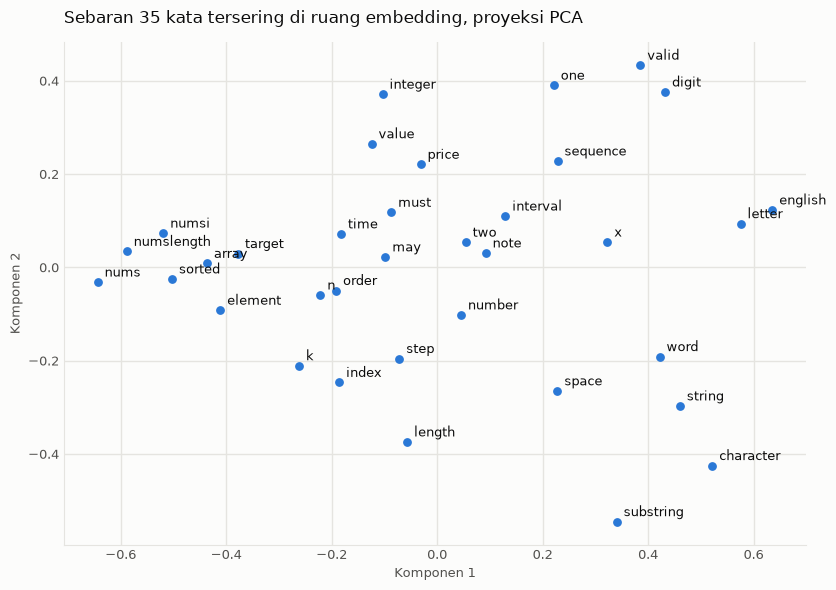

In [10]:
JUMLAH_KATA = 35
kata_sering = [w for w, _ in frekuensi.most_common(60) if w in indeks_kata][:JUMLAH_KATA]
titik = PCA(n_components=2, random_state=42).fit_transform(E[[indeks_kata[w] for w in kata_sering]])

SURFACE, TEKS_UTAMA, TEKS_SEKUNDER, GARIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"

fig, ax = plt.subplots(figsize=(8.5, 6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

ax.scatter(titik[:, 0], titik[:, 1], s=28, color="#2a78d6", zorder=3)
for (x, y), kata in zip(titik, kata_sering):
    ax.annotate(kata, (x, y), xytext=(5, 4), textcoords="offset points",
                fontsize=9, color=TEKS_UTAMA)

ax.set_title(f"Sebaran {JUMLAH_KATA} kata tersering di ruang embedding, proyeksi PCA",
             fontsize=12, color=TEKS_UTAMA, pad=14, loc="left")
ax.set_xlabel("Komponen 1", fontsize=9, color=TEKS_SEKUNDER)
ax.set_ylabel("Komponen 2", fontsize=9, color=TEKS_SEKUNDER)
ax.grid(True, color=GARIS, linewidth=1, linestyle="-")
ax.set_axisbelow(True)
for sisi in ("top", "right"):
    ax.spines[sisi].set_visible(False)
for sisi in ("left", "bottom"):
    ax.spines[sisi].set_color(GARIS)
ax.tick_params(colors=TEKS_SEKUNDER, length=0, labelsize=9)

plt.tight_layout()
plt.show()

## Tahap 10: Dari Vektor Kata ke Vektor Dokumen

Ada satu masalah praktis. Word2Vec memberi satu vektor per kata, sedangkan
klasifikasi butuh satu vektor per dokumen.

Cara paling umum untuk menjembatani itu adalah merata ratakan vektor semua kata
dalam dokumen tersebut. Hasilnya satu vektor 50 dimensi yang mewakili keseluruhan
soal.

Cara ini punya kelemahan yang perlu disebut kalau ditanya: urutan kata hilang
sepenuhnya, dan kata penting tenggelam oleh kata biasa karena semuanya dirata
ratakan dengan bobot sama. Ada cara yang lebih baik, misalnya memberi bobot TF-IDF
saat merata ratakan, atau memakai Doc2Vec. Rata rata biasa dipakai di sini karena
paling sederhana dan paling mudah dijelaskan.

In [11]:
def vektor_dokumen(dokumen):
    """Rata ratakan vektor semua kata yang ada di kosakata."""
    vektor = [E[indeks_kata[w]] for w in dokumen if w in indeks_kata]
    if not vektor:
        return np.zeros(DIM)
    return np.mean(vektor, axis=0)


X_embed = np.vstack([vektor_dokumen(dok) for dok in korpus_kata])
y_label = df['Difficulty'].values

print(f"Matriks dokumen : {X_embed.shape}  (dokumen x dimensi)")
print(f"Sel bernilai nol: {100 * (X_embed == 0).mean():.1f} persen")
print(f"\nSebagai pembanding, TF-IDF di notebook 2 berukuran 90 x 424 "
      f"dengan sekitar 94 persen sel bernilai nol.")

Matriks dokumen : (90, 50)  (dokumen x dimensi)
Sel bernilai nol: 0.0 persen

Sebagai pembanding, TF-IDF di notebook 2 berukuran 90 x 424 dengan sekitar 94 persen sel bernilai nol.


## Tahap 11: Mengukur Kemiripan Antar Soal

Sekarang tiap soal punya vektornya sendiri, jadi kemiripan antar soal bisa
dihitung.

Ini bagian yang paling enak ditunjukkan saat presentasi, karena hasilnya bisa
langsung dinilai benar atau tidak oleh siapa pun yang membacanya. Soal yang
dipasangkan model memang soal yang temanya mirip, padahal model tidak pernah
melihat judulnya sama sekali, hanya teks deskripsinya.

In [12]:
# Normalisasi dulu supaya perkalian titik = cosine similarity
En = X_embed / (np.linalg.norm(X_embed, axis=1, keepdims=True) + 1e-9)
kemiripan = En @ En.T
np.fill_diagonal(kemiripan, -9)        # jangan cocokkan soal dengan dirinya sendiri

print("Soal paling mirip menurut embedding:\n")
for i in range(5):
    j = int(np.argmax(kemiripan[i]))
    print(f"  {df['Problem Name'][i]}")
    print(f"     paling mirip dengan: {df['Problem Name'][j]}  ({kemiripan[i, j]:.2f})\n")

Soal paling mirip menurut embedding:



  Two Sum
     paling mirip dengan: 3Sum Closest  (0.96)

  Longest Substring Without Repeating Characters
     paling mirip dengan: Longest Palindromic Substring  (0.86)

  Median of Two Sorted Arrays
     paling mirip dengan: Merge Sorted Array  (0.96)

  Longest Palindromic Substring
     paling mirip dengan: Longest Valid Parentheses  (0.86)

  Zigzag Conversion
     paling mirip dengan: Regular Expression Matching  (0.78)



## Tahap 12: Membandingkan dengan TF-IDF

Rangkuman perbedaan keduanya, memakai angka nyata dari project ini.

**Yang divektorkan.** TF-IDF langsung mengubah dokumen jadi vektor. Word2Vec
mengubah kata jadi vektor, lalu vektor dokumen dibentuk dengan merata ratakan.

**Jumlah dimensi.** TF-IDF butuh 424 kolom, satu untuk tiap kata di kosakata.
Embedding cukup 50 kolom berapa pun jumlah katanya.

**Kepadatan.** Matriks TF-IDF sekitar 94 persen berisi nol. Matriks embedding
hampir seluruhnya terisi.

**Makna kata.** Ini perbedaan yang paling mendasar. Di TF-IDF, `sorted` dan
`ascending` adalah dua kolom terpisah tanpa hubungan apa pun. Di embedding,
keduanya berdekatan karena sering muncul di konteks yang sama.

**Keterbacaan.** TF-IDF gampang ditelusuri, tiap kolom jelas mewakili kata apa.
Dimensi embedding tidak punya arti yang bisa dinamai satu per satu.

**Kebutuhan data.** TF-IDF tetap masuk akal di data kecil. Word2Vec baru benar
benar kuat kalau korpusnya besar, dan itu terlihat dari analogi yang gagal di
Tahap 8.

Sel di bawah mencetak perbandingan angkanya langsung dari kedua matriks.

In [13]:
FILE_TFIDF = DATASET_DIR / "vectorized" / "X_tfidf.npz"

print(f"{'Aspek':<26}{'TF-IDF':>16}{'Word Embedding':>18}")
print("=" * 60)

if FILE_TFIDF.exists():
    import scipy.sparse as sp
    X_tfidf = sp.load_npz(FILE_TFIDF)
    nol_tfidf = 100 * (1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]))
    print(f"{'Ukuran matriks':<26}{str(X_tfidf.shape):>16}{str(X_embed.shape):>18}")
    print(f"{'Jumlah dimensi':<26}{X_tfidf.shape[1]:>16}{X_embed.shape[1]:>18}")
    print(f"{'Sel bernilai nol':<26}{nol_tfidf:>15.1f}%{100 * (X_embed == 0).mean():>17.1f}%")
else:
    print("  (jalankan 02_Vektorisasi.ipynb dulu untuk pembanding TF-IDF)")
    print(f"{'Ukuran matriks':<26}{'-':>16}{str(X_embed.shape):>18}")

print(f"{'Kemiripan antar kata':<26}{'tidak ada':>16}{'bisa dihitung':>18}")
print(f"{'Dimensi bisa dinamai':<26}{'ya':>16}{'tidak':>18}")

Aspek                               TF-IDF    Word Embedding
Ukuran matriks                   (90, 424)          (90, 50)
Jumlah dimensi                         424                50
Sel bernilai nol                     94.4%              0.0%
Kemiripan antar kata             tidak ada     bisa dihitung
Dimensi bisa dinamai                    ya             tidak


## Tahap 13: Menyimpan Hasil

Tiga berkas disimpan ke `Dataset/embedding/`.

`word2vec_model.npz` berisi matriks bobot dan daftar kosakatanya. Ini juga yang
dibaca sebagai cache saat notebook dijalankan ulang.

`X_embedding.npz` berisi matriks dokumen berukuran 90 kali 50 beserta labelnya,
siap dipakai untuk klasifikasi.

`vektor_kata.xlsx` berisi vektor tiap kata dalam bentuk tabel biasa, supaya bisa
dibuka dan dilihat langsung tanpa kode.

In [14]:
# 1. Model, sekaligus jadi cache untuk menjalankan ulang notebook ini
np.savez(FILE_MODEL, W_in=W_in, kosakata=np.array(kosakata, dtype=object))

# 2. Vektor dokumen beserta labelnya, siap untuk tahap klasifikasi
np.savez(EMBED_DIR / "X_embedding.npz", X=X_embed, y=y_label)

# 3. Vektor tiap kata dalam bentuk tabel yang bisa dibuka manusia
pd.DataFrame(
    np.round(E, 4),
    index=kosakata,
    columns=[f"dim_{i}" for i in range(DIM)]
).to_excel(EMBED_DIR / "vektor_kata.xlsx")

print("Tersimpan di", EMBED_DIR, "\n")
for berkas in sorted(EMBED_DIR.iterdir()):
    print(f"  {berkas.name:<26} {berkas.stat().st_size / 1024:>8.1f} KB")

Tersimpan di /Users/alif/PycharmProjects/Text-Mining/Dataset/embedding 

  X_embedding.npz                36.0 KB
  vektor_kata.xlsx              123.4 KB
  word2vec_model.npz            176.9 KB


### Membuktikan hasilnya bisa dipakai lagi

Sel penutup memuat ulang berkas yang baru ditulis, memastikan isinya utuh dan siap
dipakai notebook klasifikasi nanti.

In [15]:
dimuat = np.load(EMBED_DIR / "X_embedding.npz", allow_pickle=True)
X_cek, y_cek = dimuat['X'], dimuat['y']

print(f"X dimuat : {X_cek.shape}")
print(f"y dimuat : {y_cek.shape}, kelas {sorted(set(y_cek))}")
print(f"Sama dengan X asli: {np.allclose(X_cek, X_embed)}")

X dimuat : (90, 50)
y dimuat : (90,), kelas ['Easy', 'Hard', 'Medium']
Sama dengan X asli: True


## Ringkasan

Notebook ini melatih Word2Vec Skip-gram with Negative Sampling di atas 90 soal
LeetCode, menghasilkan vektor 50 dimensi untuk tiap kata, lalu mengubahnya jadi
vektor per dokumen dengan merata ratakan.

Yang berhasil ditunjukkan: kata satu topik berkumpul berdekatan, dan soal yang
temanya mirip terdeteksi mirip walau model cuma melihat teks deskripsinya.

Yang belum tercapai: analogi vektor, karena korpusnya terlalu kecil.

### Alur tiga notebook

```
01_Pengambilan_Data.ipynb
    scraping, cleaning, tokenizing, filtering, lemmatization
        |
        v
    Dataset/dataset_leetcode_cleaned.xlsx
        |
        |======================|
        |                      |
        v                      v
02_Vektorisasi.ipynb     03_Word_Embedding.ipynb
    Bag of Words             Word2Vec Skip-gram
    TF-IDF                   vektor kata 50 dimensi
    N-gram                   vektor dokumen
        |                      |
        v                      v
  Dataset/vectorized/    Dataset/embedding/
        |                      |
        |==========|===========|
                   v
        tahap berikutnya: klasifikasi
```

### Langkah berikutnya

Dua representasi sekarang tersedia, dan keduanya bisa dibandingkan hasil
klasifikasinya:

```python
import numpy as np, scipy.sparse as sp
from sklearn.model_selection import train_test_split

# Representasi 1, dari notebook 2
X_tfidf = sp.load_npz("Dataset/vectorized/X_tfidf.npz")

# Representasi 2, dari notebook ini
d = np.load("Dataset/embedding/X_embedding.npz", allow_pickle=True)
X_embed, y = d['X'], d['y']

X_train, X_test, y_train, y_test = train_test_split(
    X_embed, y, test_size=0.2, random_state=42, stratify=y
)
```

### Catatan tentang gensim

Di luar project ini, Word2Vec biasanya dipanggil lewat gensim dengan dua baris:

```python
from gensim.models import Word2Vec
model = Word2Vec(korpus_kata, vector_size=50, window=5, min_count=3, sg=1)
model.wv.most_similar("array")
```

Hasilnya setara dengan yang dikerjakan notebook ini, hanya saja prosesnya
tersembunyi. Gensim tidak dipakai di sini karena belum menyediakan wheel untuk
Python 3.14, sehingga pemasangannya butuh kompilasi lewat Xcode.